### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [86]:
data = pd.read_csv('data/coupons.csv')

In [87]:
data.head(50)

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
5,No Urgent Place,Friend(s),Sunny,80,6PM,Restaurant(<20),2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
6,No Urgent Place,Friend(s),Sunny,55,2PM,Carry out & Take away,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
7,No Urgent Place,Kid(s),Sunny,80,10AM,Restaurant(<20),2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
8,No Urgent Place,Kid(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [88]:
# Check the dataset's size, column types, and non-missing counts
print("-----Check the dataset's size, column types, and non-missing counts")
print("Dataset shape:", data.shape)
data.info()

# Count missing values in each column
print("-----Count missing values in each column")
display(data.isna().sum().sort_values(ascending=False))

# Count duplicate rows
print("Count duplicate rows")
print("Duplicate rows:", data.duplicated().sum())

# Review numeric columns for unusual ranges or values
print("-----Review numeric columns for unusual ranges or values")
display(data.describe().T)

#Preview rows containing missing values 
print("-----Preview rows containing missing values")
display(data[data.isna().any(axis=1)].head())

-----Check the dataset's size, column types, and non-missing counts
Dataset shape: (12684, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  obj

car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
weather                     0
temperature                 0
destination                 0
passanger                   0
maritalStatus               0
age                         0
gender                      0
expiration                  0
coupon                      0
time                        0
income                      0
occupation                  0
has_children                0
education                   0
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

Count duplicate rows
Duplicate rows: 74
-----Review numeric columns for unusual ranges or values


,count,mean,std,min,25%,50%,75%,max
temperature,12684.0,63.301798,19.154486,30.0,55.0,80.0,80.0,80.0
has_children,12684.0,0.414144,0.492593,0.0,0.0,0.0,1.0,1.0
toCoupon_GEQ5min,12684.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
toCoupon_GEQ15min,12684.0,0.561495,0.496224,0.0,0.0,1.0,1.0,1.0
toCoupon_GEQ25min,12684.0,0.119126,0.323950,0.0,0.0,0.0,0.0,1.0
direction_same,12684.0,0.214759,0.410671,0.0,0.0,0.0,0.0,1.0
direction_opp,12684.0,0.785241,0.410671,0.0,1.0,1.0,1.0,1.0
Y,12684.0,0.568433,0.495314,0.0,0.0,1.0,1.0,1.0


-----Preview rows containing missing values


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


3. Decide what to do about your missing data -- drop, replace, other...

In [89]:
# Find missing values in each column
data.isna().sum()

# Find total missing values in the whole dataset
data.isna().sum().sum()

print("Overall missing %:", data.isna().sum().sum() / data.size * 100)

missing_data_columns = data.isna().sum().sort_values(ascending=False)
missing_data_columns = missing_data_columns[missing_data_columns > 0]
print(missing_data_columns)

# Work on a copy so the original data stays unchanged
NewData = data.copy()

# Find missing values and drop the column with the most('Car'column)
missing_counts = NewData.isna().sum()
columns_with_missing = missing_counts[missing_counts > 0]

if not columns_with_missing.empty:
    column_to_drop = columns_with_missing.idxmax()
    NewData = NewData.drop(columns=column_to_drop)

# Recheck which remaining columns still have missing values
columns_with_missing = NewData.columns[NewData.isna().any()]

# Replace remaining missing values with each column's mode
for column in columns_with_missing:
    mode_values = NewData[column].mode()
    if not mode_values.empty:
        NewData[column] = NewData[column].fillna(mode_values.iloc[0])

# Recheck for any remaining missing values
print(NewData.isna().sum().sort_values(ascending=False))
print(NewData)

# Will be using NewData for all the data analysis and modeling tasks going forward in this assignment.


Overall missing %: 4.054168789268127
car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
dtype: int64
destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64
           destination  passanger weather  temperature  time  \
0      No Urgent Place      Alone   Sunny  

4. What proportion of the total observations chose to accept the coupon?



Y
1    7210
0    5474
Name: count, dtype: int64


<Axes: title={'center': 'Coupon Acceptance Proportion'}, ylabel='count'>

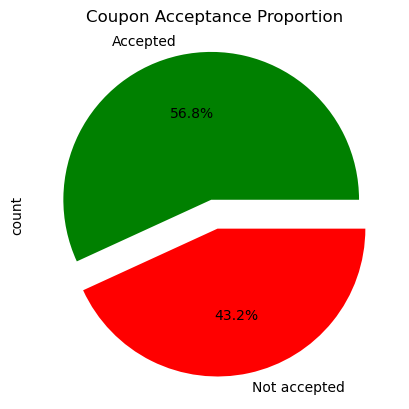

In [90]:
#Count the number of accepted and not accepted coupons
CountY = NewData['Y'].value_counts()
print(CountY)

#Pie chart to visualize the proportion of accepted vs not accepted coupons
NewData['Y'].value_counts().plot(
    kind='pie', 
    labels = ['Accepted','Not accepted'],
    explode = [0.1, 0.1],
    autopct ='%1.1f%%', 
    colors = ['g', 'r'],
    title ="Coupon Acceptance Proportion"
)


5. Use a bar plot to visualize the `coupon` column.

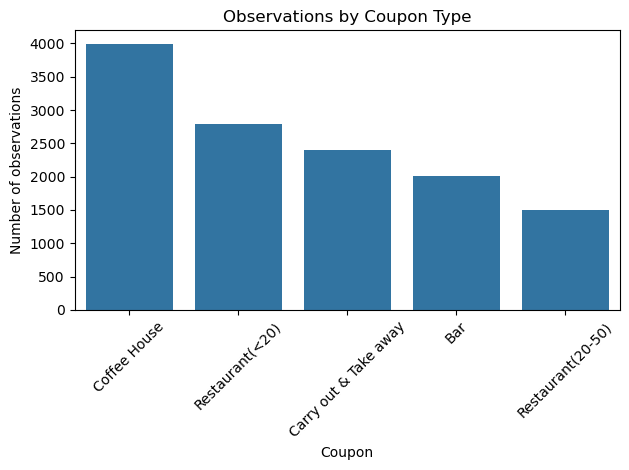

In [91]:
#Bar chart to visualize the number of observations for each coupon type
#NewData["coupon"].value_counts().plot(kind="bar")
sns.countplot(data=NewData, x="coupon",
              order=NewData["coupon"].value_counts().index)

plt.xlabel("Coupon")
plt.ylabel("Number of observations")
plt.title("Observations by Coupon Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

0        55
1        80
2        80
3        80
4        80
         ..
12679    55
12680    55
12681    30
12682    30
12683    80
Name: temperature, Length: 12684, dtype: int64


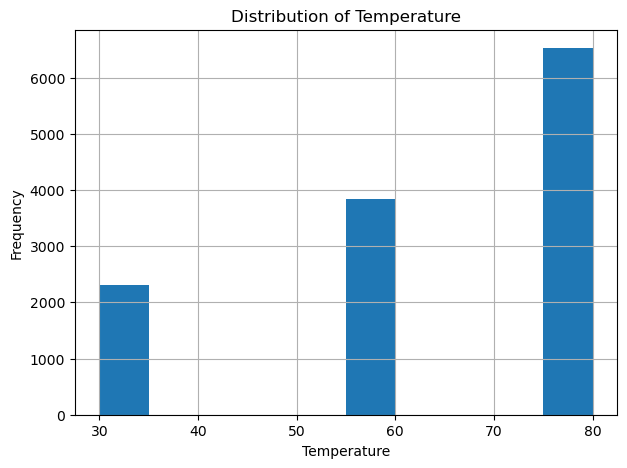

In [92]:
#Histogram to visualize the distribution of temperature
print(NewData["temperature"])

plt.figure(figsize = (7,5))
NewData["temperature"].hist(bins=10),
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Temperature")
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [93]:
# bar_coupons `DataFrame` that contains just the bar coupons
bar_coupons = NewData[NewData["coupon"] == "Bar"].copy()
bar_coupons

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12663,No Urgent Place,Friend(s),Sunny,80,10PM,Bar,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12664,No Urgent Place,Friend(s),Sunny,55,10PM,Bar,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12667,No Urgent Place,Alone,Rainy,55,10AM,Bar,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12670,No Urgent Place,Partner,Rainy,55,6PM,Bar,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0


2. What proportion of bar coupons were accepted?


Y
0    1190
1     827
Name: count, dtype: int64


<Axes: title={'center': 'Bar Coupon Acceptance'}>

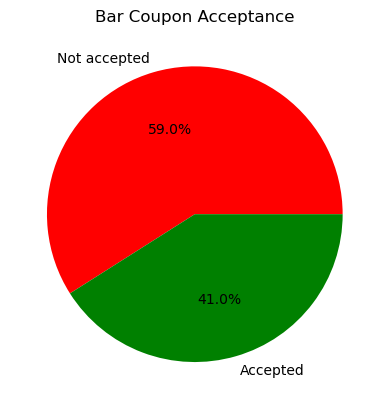

In [94]:
#Count the number of accepted and not accepted coupons
CountBar_coupons = bar_coupons['Y'].value_counts()
print(CountBar_coupons)

# If accepted coupons are marked 1 in the Y column, proportion is calculate like this:

bar_coupons["Y"].mean() * 100

bar_coupons['Y'].value_counts().plot(
    kind="pie",
    labels=["Not accepted", "Accepted"],
    autopct="%1.1f%%",
    colors = ['r', 'g'],
    ylabel="",
    title="Bar Coupon Acceptance")

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


Y
0    1144
1     674
Name: count, dtype: int64
Y
1    153
0     46
Name: count, dtype: int64
3 or fewer: 37.1%
More than 3: 76.9%


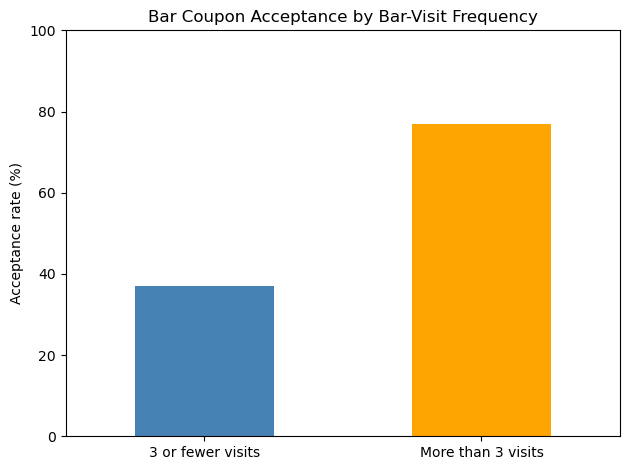

In [95]:
#Filter the DataFrame to rows where the coupon column is "Bar". bar_coupons is a new DataFrame containing only bar coupon observations.
bar_coupons = NewData[NewData["coupon"] == "Bar"]

# selects people whose bar-visit frequency is "never", "less1" (less than once a month), or "1~3" times a month.

three_or_fewer = bar_coupons[
    bar_coupons["Bar"].isin(["never", "less1", "1~3"])
]

#Shows the number of people in this group who accepted (1) and did not accept (0).
print(three_or_fewer['Y'].value_counts())

# Selects people who visit a bar "4~8" or more than "8" times a month.
more_than_three = bar_coupons[
    bar_coupons["Bar"].isin(["4~8", "gt8"])
]

#Shows the number of people in this group who accepted (1) and did not accept (0).
print(more_than_three['Y'].value_counts())

#Calculates and prints each group’s acceptance rate. Since Y is coded 1 for accepted and 0 for not accepted, its average is the fraction who accepted; :.1% displays that fraction as a percentage
print("3 or fewer:", f"{three_or_fewer['Y'].mean():.1%}")
print("More than 3:", f"{more_than_three['Y'].mean():.1%}")

#Bar chart to show the percentage of drivers in that group who accepted the coupon.
rates = pd.Series({
    "3 or fewer visits": three_or_fewer["Y"].mean() * 100,
    "More than 3 visits": more_than_three["Y"].mean() * 100
})

rates.plot(kind="bar", color=["steelblue", "orange"])
plt.ylabel("Acceptance rate (%)")
plt.title("Bar Coupon Acceptance by Bar-Visit Frequency")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Bar more than once/month and over 25: 62.2%
All others: 55.4%
Difference: 6.8 percentage points


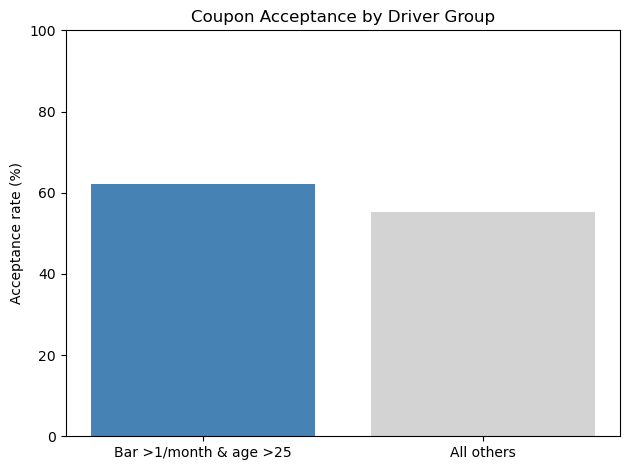

In [96]:
#Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?
# Dataframes for drivers who go to a bar more than once a month and are over the age of 25 to the all other
goes_to_bar_often = NewData["Bar"].isin(["1~3", "4~8", "gt8"])
over_25 = NewData["age"].isin(["26", "31", "36", "41", "46", "50plus"])

#Dataframe for drivers who go to a bar more than once a month and are over the age of 25
target_group = goes_to_bar_often & over_25

#selects the Y values for rows where target_group is True and applies mean()to get averages of those values. Because Y is 1 for accepted and 0 for not accepted, the average is the acceptance rate.
target_rate = NewData.loc[target_group, "Y"].mean()
other_rate = NewData.loc[~target_group, "Y"].mean()

print(f"Bar more than once/month and over 25: {target_rate:.1%}")
print(f"All others: {other_rate:.1%}")
print(f"Difference: {(target_rate - other_rate) * 100:.1f} percentage points")

#Bar chart to compare the acceptance rates for the target group and everyone else:
plt.bar(
    ["Bar >1/month & age >25", "All others"],
    [target_rate * 100, other_rate * 100],
    color=["steelblue", "lightgray"]
)

plt.ylabel("Acceptance rate (%)")
plt.title("Coupon Acceptance by Driver Group")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


Target group acceptance rate: 62.3%
All others acceptance rate: 54.6%
Difference: 7.7 percentage points


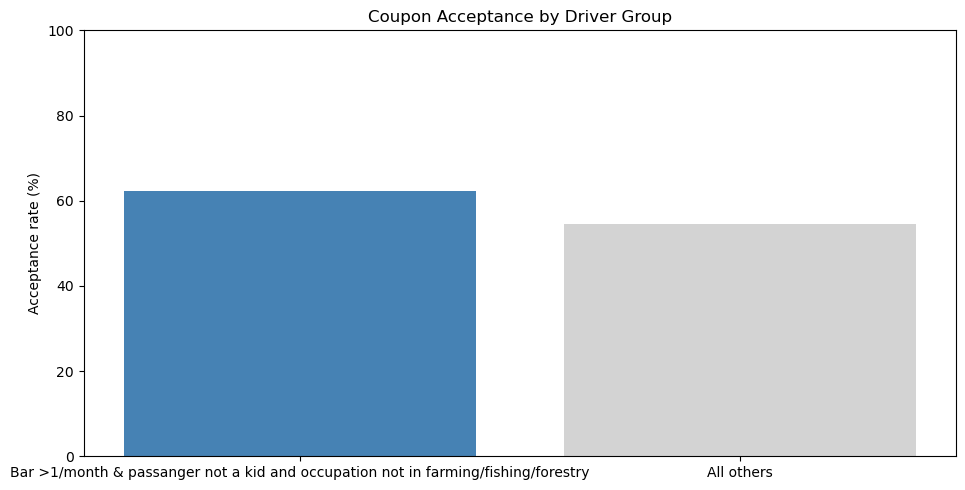

In [97]:
#Dataframes for drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry
goes_to_bar_often = NewData["Bar"].isin(["1~3", "4~8", "gt8"])
not_with_a_kid = NewData["passanger"] != "Kid(s)"
other_occupation = NewData["occupation"] != "Farming Fishing & Forestry"

# This combines three True/False filters to identify rows that meet all three conditions
target_group = goes_to_bar_often & not_with_a_kid & other_occupation

target_rate = NewData.loc[target_group, "Y"].mean()
other_rate = NewData.loc[~target_group, "Y"].mean()

print(f"Target group acceptance rate: {target_rate:.1%}")
print(f"All others acceptance rate: {other_rate:.1%}")
print(f"Difference: {(target_rate - other_rate) * 100:.1f} percentage points")

#Bar chart to compare the acceptance rates for the target group and everyone else:
plt.figure(figsize = (10,5))
plt.bar(
    ["Bar >1/month & passanger not a kid and occupation not in farming/fishing/forestry", "All others"],
    [target_rate * 100, other_rate * 100],
    color=["steelblue", "lightgray"]
)

plt.ylabel("Acceptance rate (%)")
plt.title("Coupon Acceptance by Driver Group")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



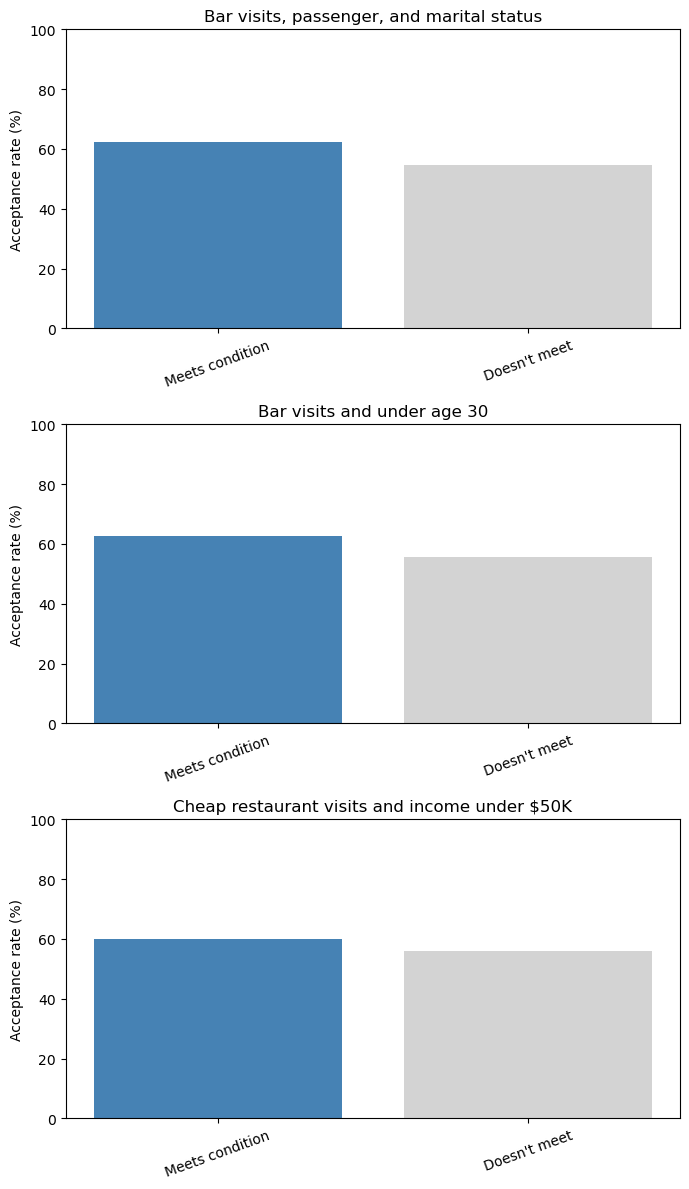

In [98]:
# Create a mask for each of the three conditions, combine them with | (“or”), then compare the acceptance rate for drivers who meet at least one condition with everyone else:

bar_more_than_once = NewData["Bar"].isin(["1~3", "4~8", "gt8"])

#Dataframe for those who go to bars more than once a month, had passengers that were not a kid, and were not widowed
group1 = (
    bar_more_than_once
    & NewData["passanger"].notna()
    & NewData["passanger"].ne("Kid(s)")
    & NewData["maritalStatus"].notna()
    & NewData["maritalStatus"].ne("Widowed")
)

#Dataframe for those who go to bars more than once a month and are under the age of 30
group2 = bar_more_than_once & NewData["age"].isin(["below21", "21", "26"])

#Dataframe for those who go to cheap restaurants more than 4 times a month and income is less than 50K
group3 = (
    NewData["RestaurantLessThan20"].isin(["4~8", "gt8"])
    & NewData["income"].isin([
        "Less than $12500",
        "$12500 - $24999",
        "$25000 - $37499",
        "$37500 - $49999",
    ])
)

driversGroup = [group1, group2, group3]
titles = [
    "Bar visits, passenger, and marital status",
    "Bar visits and under age 30",
    "Cheap restaurant visits and income under $50K"
]

#creates a layout of 1 row and 3 charts. figsize sets the overall chart size, and sharey=True gives them a common y-axis scale.
fig, axes = plt.subplots(3, 1, figsize=(7,12), sharey=True)

#For loop pairs each chart (ax) with a condition (mask) and its title.
for ax, driversGroup, title in zip(axes, driversGroup, titles):
    #calculates the acceptance percentage for drivers who meet the condition. ~driversGroup selects everyone who doesn’t meet it.
    rates = [
        NewData.loc[driversGroup, "Y"].mean() * 100,
        NewData.loc[~driversGroup, "Y"].mean() * 100
    ]

# draws two bars for those percentages.

    ax.bar(["Meets condition", "Doesn't meet"], rates,
           color=["steelblue", "lightgray"])
    ax.set_title(title)
    ax.set_ylabel("Acceptance rate (%)")
    ax.set_ylim(0, 100)
    #tick_paramstilts the x-axis labels for readability.
    ax.tick_params(axis="x", labelrotation=20)

plt.tight_layout()
plt.show()


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

#Drivers who visit bars more often may be more likely to accept bar coupons, since the offer fits their habits.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

Y
1    1760
0     633
Name: count, dtype: int64


<Axes: title={'center': 'Carry Out & Take Away Coupon Acceptance'}>

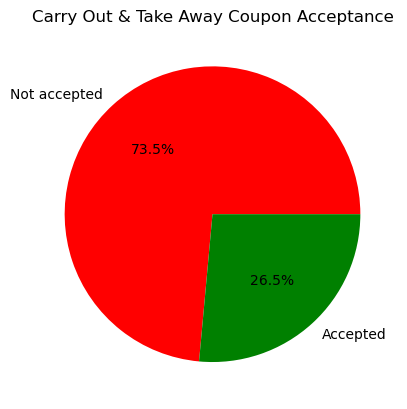

In [99]:
# What proportion of the total observations chose to accept the coupon?
# bar_coupons `DataFrame` that contains just the bar coupons
Carry_away_coupons = NewData[NewData["coupon"] == "Carry out & Take away"].copy()
Carry_away_coupons

#Count the number of accepted and not accepted coupons
CountCarry_away_coupons = Carry_away_coupons['Y'].value_counts()
print(CountCarry_away_coupons)

# If accepted coupons are marked 1 in the Y column, proportion is calculate like this:

Carry_away_coupons["Y"].mean() * 100
Carry_away_coupons
Carry_away_coupons['Y'].value_counts().plot(
    kind="pie",
    labels=["Not accepted", "Accepted"],
    autopct="%1.1f%%",
    colors = ['r', 'g'],
    ylabel="",
    title="Carry Out & Take Away Coupon Acceptance")

Y
1    1579
0     554
Name: count, dtype: int64
Y
1    181
0     79
Name: count, dtype: int64
3 or fewer: 74.0%
More than 3: 69.6%


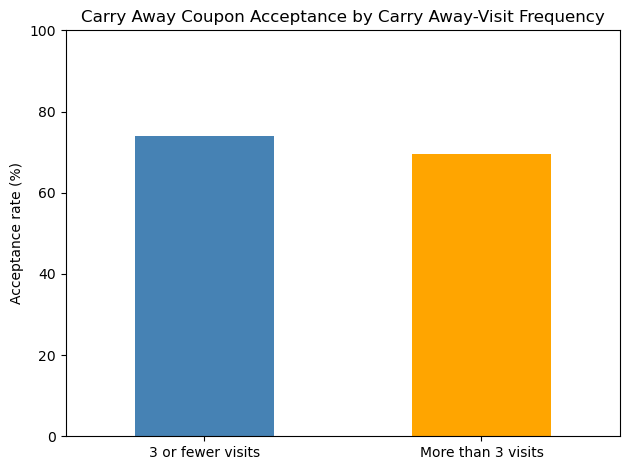

In [100]:
#Find all the unique values for column "CarryAway" in the DataFrame NewData. This will help you understand the different categories or values present in that column.
NewData["CarryAway"].unique()

#Filter the DataFrame to rows where the coupon column is "CarryAway". CarryAway_coupons is a new DataFrame containing only bar coupon observations.
carryAway_coupons = NewData[NewData["coupon"] == "Carry out & Take away"]

# selects people whose bar-visit frequency is "never", "less1" (less than once a month), or "1~3" times a month.

three_or_fewer = carryAway_coupons[
    carryAway_coupons["Bar"].isin(["never", "less1", "1~3"])
]

#Shows the number of people in this group who accepted (1) and did not accept (0).
print(three_or_fewer['Y'].value_counts())

# Selects people who visit a bar "4~8" or more than "8" times a month.
more_than_three = carryAway_coupons[
    carryAway_coupons["Bar"].isin(["4~8", "gt8"])
]

#Shows the number of people in this group who accepted (1) and did not accept (0).
print(more_than_three['Y'].value_counts())

#Calculates and prints each group’s acceptance rate. Since Y is coded 1 for accepted and 0 for not accepted, its average is the fraction who accepted; :.1% displays that fraction as a percentage
print("3 or fewer:", f"{three_or_fewer['Y'].mean():.1%}")
print("More than 3:", f"{more_than_three['Y'].mean():.1%}")

#Bar chart to show the percentage of drivers in that group who accepted the coupon.
rates = pd.Series({
    "3 or fewer visits": three_or_fewer["Y"].mean() * 100,
    "More than 3 visits": more_than_three["Y"].mean() * 100
})

rates.plot(kind="bar", color=["steelblue", "orange"])
plt.ylabel("Acceptance rate (%)")
plt.title("Carry Away Coupon Acceptance by Carry Away-Visit Frequency")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

CarryAway more than once/month and over 41: 56.6%
All others: 56.9%
Difference: -0.3 percentage points


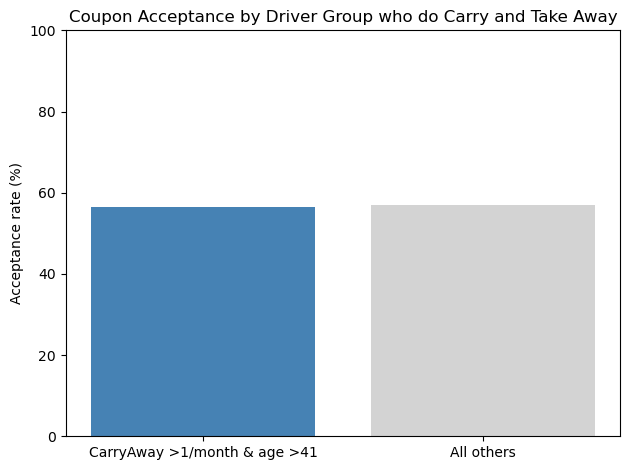

In [101]:

#Compare the acceptance rate between drivers who do Carry and Take more than once a month and are over the age of 25 to the all others.  Is there a difference?
# Dataframes for drivers who go to a bar more than once a month and are over the age of 36 to the all other
does_take_away_often = NewData["CarryAway"].isin(["1~3", "4~8", "gt8"])
over_41 = NewData["age"].isin([ "41", "46", "50plus"])

#Dataframe for drivers who go to a bar more than once a month and are over the age of 36
target_group1 = does_take_away_often & over_41

#selects the Y values for rows where target_group is True and applies mean()to get averages of those values. Because Y is 1 for accepted and 0 for not accepted, the average is the acceptance rate.
target_rate1 = NewData.loc[target_group1, "Y"].mean()
other_rate1 = NewData.loc[~target_group1, "Y"].mean()

print(f"CarryAway more than once/month and over 41: {target_rate1:.1%}")
print(f"All others: {other_rate1:.1%}")
print(f"Difference: {(target_rate1 - other_rate1) * 100:.1f} percentage points")

#Bar chart to compare the acceptance rates for the target group and everyone else:
plt.bar(
    ["CarryAway >1/month & age >41", "All others"],
    [target_rate1 * 100, other_rate1 * 100],
    color=["steelblue", "lightgray"]
)

plt.ylabel("Acceptance rate (%)")
plt.title("Coupon Acceptance by Driver Group who do Carry and Take Away")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Target group acceptance rate: 33.3%
All others acceptance rate: 56.9%
Difference: -23.5 percentage points


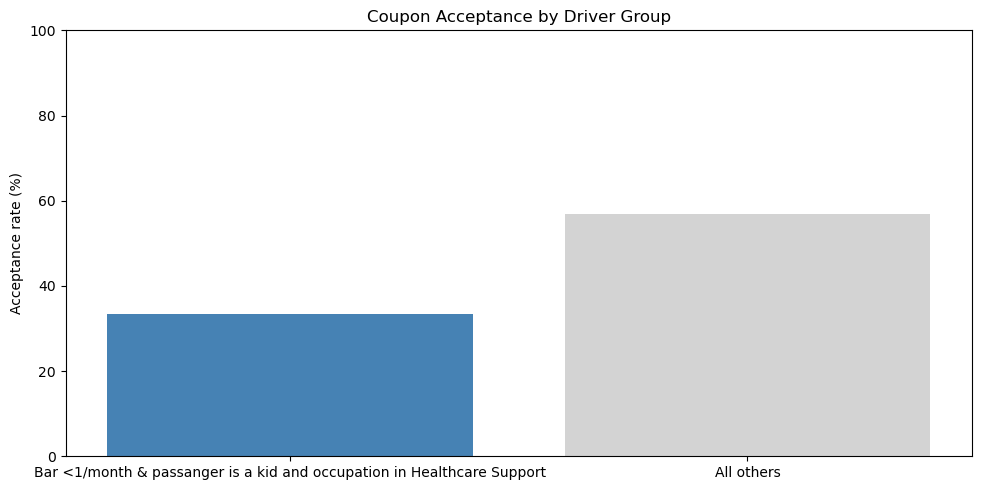

In [102]:
#compare the acceptance rate between drivers who go to bars less than once a month and had passengers that is a kid and had occupations Healthcare Support

#Dataframes for drivers who are not frequent to bars and had passengers that is a kid and had occupations of Healthcare Support
no_bar_often = NewData["Bar"].isin(["less1", "never"])
with_a_kid = NewData["passanger"].isin(["Kid(s)"])
other_occupation = NewData["occupation"].isin(["Healthcare Support"])

# This combines three True/False filters to identify rows that meet all three conditions
target_group = no_bar_often & with_a_kid & other_occupation

target_rate = NewData.loc[target_group, "Y"].mean()
other_rate = NewData.loc[~target_group, "Y"].mean()

print(f"Target group acceptance rate: {target_rate:.1%}")
print(f"All others acceptance rate: {other_rate:.1%}")
print(f"Difference: {(target_rate - other_rate) * 100:.1f} percentage points")

#Bar chart to compare the acceptance rates for the target group and everyone else:
plt.figure(figsize = (10,5))
plt.bar(
    ["Bar <1/month & passanger is a kid and occupation in Healthcare Support", "All others"],
    [target_rate * 100, other_rate * 100],
    color=["steelblue", "lightgray"]
)

plt.ylabel("Acceptance rate (%)")
plt.title("Coupon Acceptance by Driver Group")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


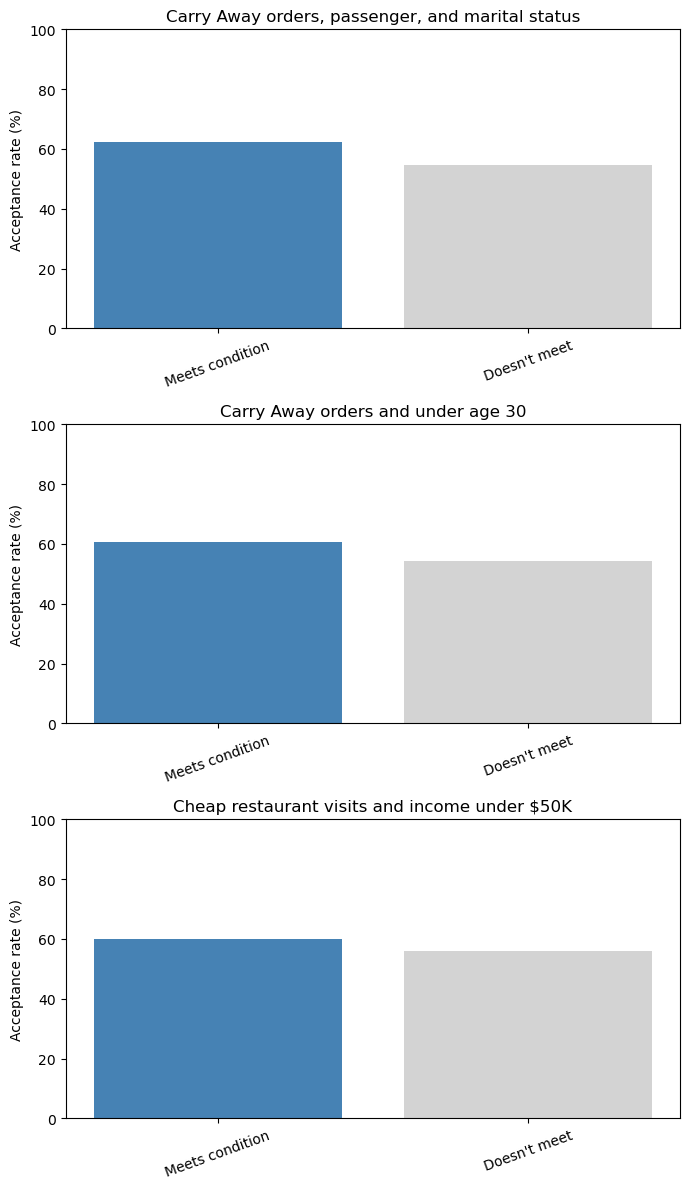

In [103]:
# Compare the acceptance rates between those drivers who:
#- carry away more than once a month, had passengers that were not a kid, and were not widowed *OR*
#- carry away more than once a month and are under the age of 30 *OR*
#- go to cheap restaurants more than 4 times a month and income is less than 50K.
# Create a mask for each of the three conditions, combine them with | (“or”), then compare the acceptance rate for drivers who meet at least one condition with everyone else:

carryAway_more_than_once = NewData["CarryAway"].isin(["1~3", "4~8", "gt8"])

#Dataframe for those who do carry aways more than once a month, had passengers that were not a kid, and were not widowed
groupA = (
    carryAway_more_than_once
    & NewData["passanger"].notna()
    & NewData["passanger"].ne("Kid(s)")
    & NewData["maritalStatus"].notna()
    & NewData["maritalStatus"].ne("Widowed")
)

#Dataframe for those who do carry aways more than once a month and are under the age of 30
group2 = carryAway_more_than_once & NewData["age"].isin(["below21", "21", "26"])

#Dataframe for those who go to cheap restaurants more than 4 times a month and income is less than 50K
group3 = (
    NewData["RestaurantLessThan20"].isin(["4~8", "gt8"])
    & NewData["income"].isin([
        "Less than $12500",
        "$12500 - $24999",
        "$25000 - $37499",
        "$37500 - $49999",
    ])
)

driversGroup = [group1, group2, group3]
titles = [
    "Carry Away orders, passenger, and marital status",
    "Carry Away orders and under age 30",
    "Cheap restaurant visits and income under $50K"
]

#creates a layout of 1 row and 3 charts. figsize sets the overall chart size, and sharey=True gives them a common y-axis scale.
fig, axes = plt.subplots(3, 1, figsize=(7,12), sharey=True)

#For loop pairs each chart (ax) with a condition (mask) and its title.
for ax, driversGroup, title in zip(axes, driversGroup, titles):
    #calculates the acceptance percentage for drivers who meet the condition. ~driversGroup selects everyone who doesn’t meet it.
    rates = [
        NewData.loc[driversGroup, "Y"].mean() * 100,
        NewData.loc[~driversGroup, "Y"].mean() * 100
    ]

# draws two bars for those percentages.

    ax.bar(["Meets condition", "Doesn't meet"], rates,
           color=["steelblue", "lightgray"])
    ax.set_title(title)
    ax.set_ylabel("Acceptance rate (%)")
    ax.set_ylim(0, 100)
    #tick_paramstilts the x-axis labels for readability.
    ax.tick_params(axis="x", labelrotation=20)

plt.tight_layout()
plt.show()


#Based on the analysis, it appears that drivers who carry away more than once a month, had passengers that were not a kid, and were not widowed, as well as those who carry away more than once a month and are under the age of 30, have higher acceptance rates for coupons compared to other groups. Additionally, drivers who go to cheap restaurants more than 4 times a month and have an income less than $50K also show a higher acceptance rate.

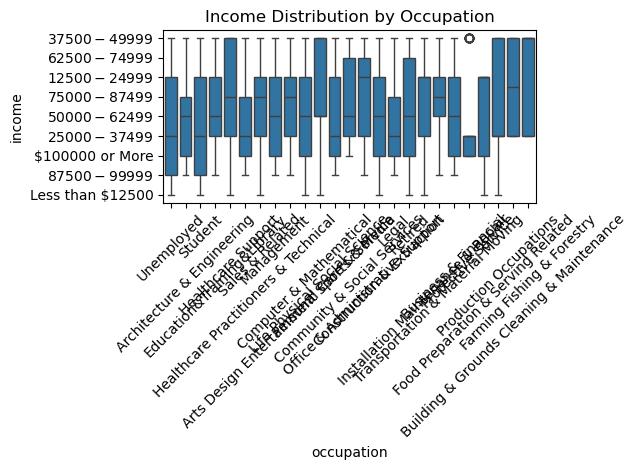

In [108]:
#using seaborn to create a boxplot to visualize the distribution of income for each occupation type. The x-axis represents the different occupation types, and the y-axis represents the income values. The boxplot provides a summary of the distribution, including the median, quartiles, and potential outliers for each occupation type.
sns.boxplot(data=NewData, x="occupation", y="income")
plt.xticks(rotation=45)
plt.title("Income Distribution by Occupation")
plt.tight_layout()
plt.show()



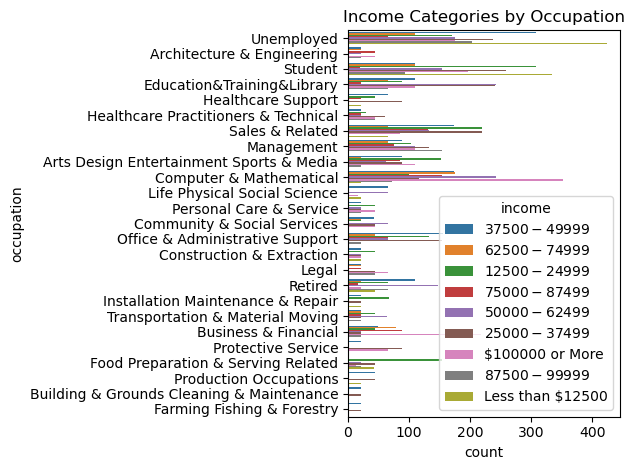

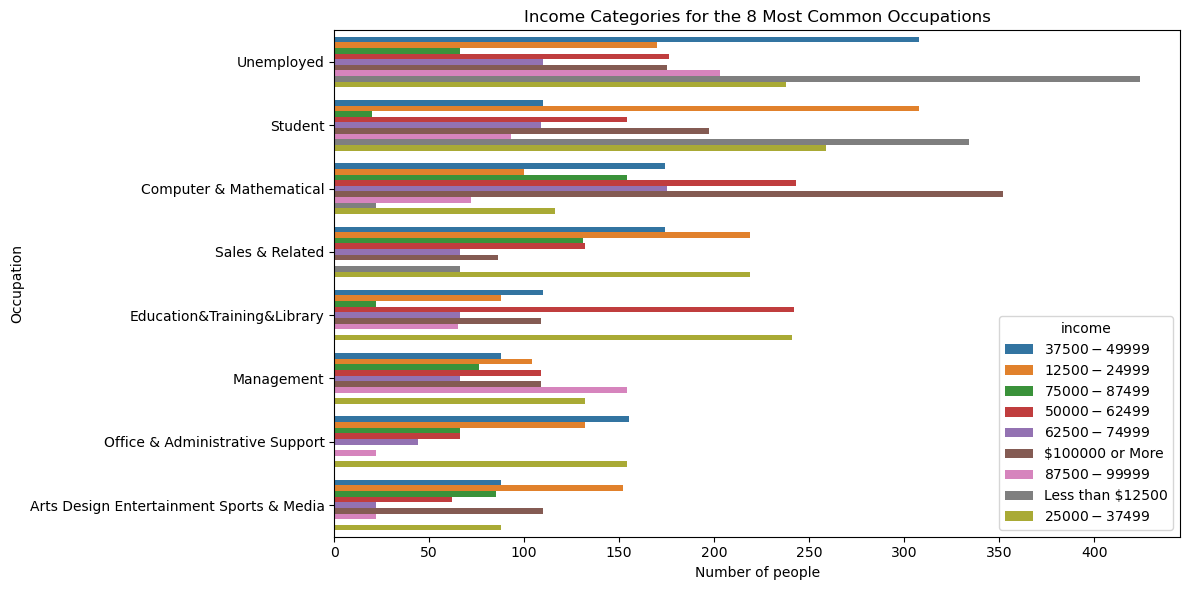

In [116]:
#Graph to visualize the count of observations for each occupation type, with separate bars for each income category. 
sns.countplot(data=NewData, y="occupation", hue="income")
plt.title("Income Categories by Occupation")
plt.tight_layout()
plt.show()

#Chart very crowded, hence showing only the top 8 occupations by count
top_occupations = NewData["occupation"].value_counts().head(8).index
plot_data = NewData[NewData["occupation"].isin(top_occupations)]

plt.figure(figsize=(12, 6))
sns.countplot(data=plot_data, y="occupation", hue="income",
              order=top_occupations)
plt.title("Income Categories for the 8 Most Common Occupations")
plt.xlabel("Number of people")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

The y-axis represents the occupation types, and the x-axis represents the count of observations. The hue parameter is used to differentiate between income categories, allowing for a comparison of income distribution across different occupations.


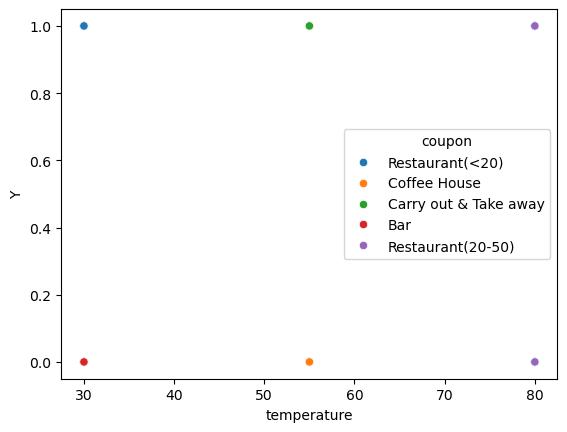

In [105]:
#Scatter plot to visualize the relationship between temperature and coupon acceptance (Y), with different colors representing different coupon types. 
sns.scatterplot(data=NewData, x="temperature", y="Y", hue="coupon")
plt.show()

The x-axis represents the temperature values, the y-axis represents the coupon acceptance (Y), and the hue parameter is used to differentiate between coupon types. This helps to explore how temperature may influence coupon acceptance across different coupon categories.